# 14 · Structure uncertainty: hypothesis sets and the factor cache

When the parents of a node are not known, we keep several **candidate parent
sets** per node.  A *hypothesis* picks one candidate per node.  A *factor* is one
pair `(node, parents)`.  With 4 nodes and 3 candidates each there are
`3^4 = 81` hypotheses but only `4 * 3 = 12` factors.  `HypothesisSet` counts,
fits and bounds every factor **once** and shares it across the hypotheses.

The example is a small *system-administrator* network (Guestrin et al., JAIR
2003): four machines on a one-way ring.  A machine that is up stays up unless
its left neighbour is down; a repaired machine comes back up.  Two behaviour
policies (loggers) each repair only one half of the ring.

- **NBN API:** `nbn.structure.HypothesisSet` (`counts`, `factor_sets`,
  `sets_for`, `model_for`); `nbn.scm.transitions_from_episodes`.
- **Runtime:** under 10 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

Ground truth (hidden from the learner), for machine `i` with left neighbour `i-1`:

    P(up'_i = 1) = 0.95                          if machine i is repaired
                 = 0.95 if up_{i-1} else 0.60     if up_i and not repaired
                 = 0.05                          if down and not repaired

In [1]:
import os

import matplotlib.pyplot as plt
import torch

from nbn.scm import transitions_from_episodes
from nbn.structure import HypothesisSet
from nbn.utils.device import resolve_device
from _figures import BLUE, ORANGE, AQUA, GREY, INK, DOUBLE, SINGLE, save, use_style

use_style()  # one style for every example: palette, sizes, fonts (_figures.py)

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)



def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


## The data: two loggers, two halves of the ring

The action is `a = 0` (do nothing) or `a = i + 1` (repair machine `i`).  Each
machine reads the action only through "am I repaired?", so we record that as a
binary input `rep_i = [a == i + 1]`.  This is a modelling choice: with the raw
5-valued action as a parent every table would have 5 times more rows.

Logger **L** repairs only machines 0 and 1, logger **R** only machines 2 and 3
(each repairs a random broken machine of its half, else does nothing).  We
pool their 150 episodes of 30 steps each.

In [2]:
N = 4                                    # machines on a one-way ring: i - 1 -> i


def p_up(up: torch.Tensor, left: torch.Tensor, rep: torch.Tensor) -> torch.Tensor:
    """True P(up'_i = 1 | up_i, up_{i-1}, rep_i)."""
    stay = torch.where(left == 1, 0.95, 0.60)
    return torch.where(rep == 1, 0.95, torch.where(up == 1, stay, 0.05))


def collect(half: tuple, n_episodes: int, horizon: int = 30, seed: int = 0) -> dict:
    gen = torch.Generator().manual_seed(seed)
    up = torch.ones(n_episodes, horizon + 1, N, dtype=torch.long)
    action = torch.zeros(n_episodes, horizon, dtype=torch.long)
    for t in range(horizon):
        broken = (up[:, t, list(half)] == 0).float()
        has_broken = broken.sum(-1) > 0
        pick = torch.multinomial(broken + 1e-9, 1, generator=gen).squeeze(-1)
        action[:, t] = torch.where(has_broken, torch.tensor(half)[pick] + 1, 0)
        rep = torch.stack([(action[:, t] == i + 1).long() for i in range(N)], -1)
        left = up[:, t].roll(1, dims=-1)
        prob = p_up(up[:, t], left, rep)
        up[:, t + 1] = torch.bernoulli(prob, generator=gen).long()
    states = {f"m{i}": up[..., i].float() for i in range(N)}
    rows = transitions_from_episodes(states, {"a": action.float()})
    for i in range(N):
        rows[f"rep{i}"] = (rows["a"] == i + 1).float()
    return rows


left_logger = collect(half=(0, 1), n_episodes=150, seed=1)
right_logger = collect(half=(2, 3), n_episodes=150, seed=2)
data = {k: torch.cat([left_logger[k], right_logger[k]]) for k in left_logger}
print("transitions:", data["m0"].numel(), "| repairs per machine:",
      [int(data[f"rep{i}"].sum()) for i in range(N)])

transitions: 9000 | repairs per machine: [834, 492, 801, 448]


## 1. Candidate parent sets and the hypothesis set

For each machine three candidates:

- **without the neighbour** `(m_i, rep_i)`: too small, misses a true parent;
- **true** `(m_i, m_{i-1}, rep_i)`;
- **two neighbours** `(m_i, m_{i-1}, m_{i+1}, rep_i)`: a superset, e.g. a
  two-way ring.

In [3]:
variables = {f"m{i}": ("discrete", 2) for i in range(N)}
variables.update({f"rep{i}": ("discrete", 2) for i in range(N)})
variables.update({f"m{i}'": ("discrete", 2) for i in range(N)})

names = ["without neighbour", "true", "two neighbours"]
candidates = {}
for i in range(N):
    left, right = f"m{(i - 1) % N}", f"m{(i + 1) % N}"
    candidates[f"m{i}'"] = [(f"m{i}", f"rep{i}"),
                            (f"m{i}", left, f"rep{i}"),
                            (f"m{i}", left, right, f"rep{i}")]

hs = HypothesisSet(variables, candidates)
print(hs)
print("one hypothesis:", next(hs.hypotheses()))

HypothesisSet(targets=4, inputs=8, factors=12, hypotheses=81)
one hypothesis: {"m0'": ('m0', 'rep0'), "m1'": ('m1', 'rep1'), "m2'": ('m2', 'rep2'), "m3'": ('m3', 'rep3')}


## 2. The factor cache and one set per factor

`factor_sets` counts every node once, over the union of its candidates'
parents, and sums down to each candidate.  The budget `delta = 0.1` is split
over the 12 distinct factors, so **all** factor sets, and hence the sets of all
81 hypotheses, hold together with probability at least 90%.  The rows are
transitions of episodes, so we use `sampling="trajectory"`.

In [4]:
fs = hs.factor_sets({k: v.to(device) for k, v in data.items()}, builder="interval",
                    delta=0.1, sampling="trajectory")
print(f"joint level {fs.level:.2f}, each factor at {1 - fs.delta_per_factor:.4f}")
print("union-and-marginalise used per node:", fs.counts.union_used)

print("\nmachine 0             rows  unseen  mean width (seen rows)")
for name, parents in zip(names, candidates["m0'"]):
    s = fs[("m0'", parents)]
    seen = ~s.unseen
    print(f"  {name:18s}  {s.unseen.numel():4d}  {int(s.unseen.sum()):6d}  {s.width()[seen].mean():.3f}")

joint level 0.90, each factor at 0.9917
union-and-marginalise used per node: {"m0'": True, "m1'": True, "m2'": True, "m3'": True}

machine 0             rows  unseen  mean width (seen rows)
  without neighbour      4       1  0.081
  true                   8       2  0.136
  two neighbours        16       4  0.285


Bigger candidates have more rows, fewer visits per row, and so wider
intervals and more unseen rows (whole simplex).  This is the price of a
superset.  The plot shows it for every machine.

without neighbour  share of rows without data, per machine: [0.25, 0.25, 0.25, 0.25]
true               share of rows without data, per machine: [0.25, 0.25, 0.25, 0.25]
two neighbours     share of rows without data, per machine: [0.25, 0.25, 0.25, 0.25]


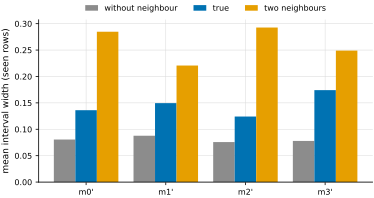

In [5]:
fig, ax_w = plt.subplots(figsize=(0.75 * DOUBLE, 2.8))
width = 0.27
for j, (name, color) in enumerate(zip(names, (GREY, BLUE, ORANGE))):
    widths, unseen = [], []
    for i in range(N):
        s = fs[(f"m{i}'", candidates[f"m{i}'"][j])]
        widths.append(float(s.width()[~s.unseen].mean()))
        unseen.append(float(s.unseen.float().mean()))
    x = [i + (j - 1) * width for i in range(N)]
    ax_w.bar(x, widths, width, color=color, label=name)
    print(f"{name:18s} share of rows without data, per machine: {[round(u, 2) for u in unseen]}")
ax_w.set(xticks=range(N), xticklabels=[f"m{i}'" for i in range(N)], ylabel="mean interval width (seen rows)")
ax_w.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
save(fig, "14_fig1")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Mean width of the 90%-joint intervals over the rows with data, for each machine and each candidate parent set. The share of rows without data (whole simplex) is printed above the plot.

## 3. Which candidates are right?

For the true parents and for the superset, the conditional probability is the
same whatever the loggers did: extra parents do not change
`P(up'_i | true parents)`.  So their intervals must contain the true value on
every seen row.  The candidate **without the neighbour** has no true table: it
averages over the neighbour with the weights of these loggers.

In [6]:
def truth_rows(parents: tuple, i: int) -> torch.Tensor:
    """True P(up'_i | parents) for every parent value (C order); only for candidates with m_{i-1}."""
    grid = torch.cartesian_prod(*[torch.arange(2)] * len(parents)).reshape(-1, len(parents))
    col = {p: grid[:, k] for k, p in enumerate(parents)}
    p1 = p_up(col[f"m{i}"], col[f"m{(i - 1) % N}"], col[f"rep{i}"])
    return torch.stack([1 - p1, p1], -1)


for name, j in (("true", 1), ("two neighbours", 2)):
    inside = []
    for i in range(N):
        parents = candidates[f"m{i}'"][j]
        s = fs[(f"m{i}'", parents)]
        ok = s.row_contains(truth_rows(parents, i).to(s.lower))[~s.unseen].all()
        inside.append(bool(ok))
    print(f"{name:15s} truth inside the intervals on every seen row, per machine: {inside}")

counts = fs.counts[("m0'", ("m0", "rep0"))]
est = counts[2] / counts[2].sum()                  # row m0=1, rep0=0 in C order over (m0, rep0)
print("\nwithout the neighbour, P(up'_0 = 1 | up_0, not repaired) =", round(float(est[1]), 3))
print("true value: 0.95 if the left neighbour is up, 0.60 if it is down")

true            truth inside the intervals on every seen row, per machine: [True, True, True, True]
two neighbours  truth inside the intervals on every seen row, per machine: [True, True, True, True]

without the neighbour, P(up'_0 = 1 | up_0, not repaired) = 0.833
true value: 0.95 if the left neighbour is up, 0.60 if it is down


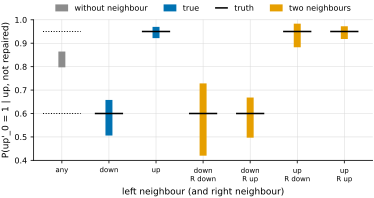

In [7]:
# Machine 0, rows "up and not repaired" under each candidate (C order over the candidate's parents).
# without neighbour (m0, rep0): one row; true (m0, m3, rep0): left down / up;
# two neighbours (m0, m3, m1, rep0): left down / up, right down / up.
ROWS = [("without neighbour", 2, None),
        ("true", 4, "down"), ("true", 6, "up"),
        ("two neighbours", 8, "down"), ("two neighbours", 10, "down"),
        ("two neighbours", 12, "up"), ("two neighbours", 14, "up")]
TICKS = ["any", "down", "up", "down\nR down", "down\nR up", "up\nR down", "up\nR up"]
TRUTH = {"down": 0.60, "up": 0.95}
colors = dict(zip(names, (GREY, BLUE, ORANGE)))
fig, ax = plt.subplots(figsize=(0.75 * DOUBLE, 2.8))
for x, (name, row, left) in enumerate(ROWS):
    s = fs[("m0'", candidates["m0'"][names.index(name)])]
    lo, hi = float(s.lower[row, 1]), float(s.upper[row, 1])
    ax.vlines(x, lo, hi, color=colors[name], lw=7, label=name if x in (0, 1, 3) else None)
    if left is not None:
        ax.hlines(TRUTH[left], x - 0.3, x + 0.3, color=INK, lw=1.5, label="truth" if x == 1 else None)
for value in TRUTH.values():
    ax.hlines(value, -0.4, 0.4, color=INK, lw=1, ls=":")
ax.set(xticks=range(len(ROWS)), xlim=(-0.6, len(ROWS) - 0.4), ylim=(0.4, 1.0),
       ylabel="P(up'_0 = 1 | up, not repaired)", xlabel="left neighbour (and right neighbour)")
ax.set_xticklabels(TICKS, fontsize=7)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4)
save(fig, "14_fig2")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Machine 0, rows where it is up and not repaired: the 90%-joint interval on `P(up'_0 = 1)` for each candidate (bars) and the truth (black). The true parents and the superset get one row per neighbour state, and every interval contains its truth (0.60 with the left neighbour down, 0.95 up). Without the neighbour there is a single row: its interval sits between the two true values (dotted) and contains neither, because it averages over the left neighbour with the loggers' weights.

## 4. A fitted model for one hypothesis

`model_for` builds a `NeuralBayesianNetwork` for one hypothesis straight from
the cached counts (no pass over the data), ready for queries.

In [8]:
true_h = {f"m{i}'": candidates[f"m{i}'"][1] for i in range(N)}
model = hs.model_for(true_h, fs.counts)
q = model.query(["m1'"], evidence={"m1": torch.tensor([1]), "m0": torch.tensor([0]),
                                   "rep1": torch.tensor([0])})
print("P(up'_1 | up_1, left neighbour down, not repaired) =",
      [round(p, 3) for p in q.reshape(-1).tolist()], " true [0.40, 0.60]")

P(up'_1 | up_1, left neighbour down, not repaired) = [0.385, 0.615]  true [0.40, 0.60]


## 5. What the hypothesis set does not do (yet)

Each hypothesis still has its own sets.  Taking the worst case over all of
them falls back to the biggest candidate, the one with the most unseen rows.
An **agreement rule** (KWIK / k-meteorologists; Simão & Spaan, IJCAI 2019)
keeps every candidate up to a declared number of parents and predicts a row
only where the surviving candidates have data and agree:
`nbn.structure.agreement_set`, notebook 15.  Continuous and mixed nodes are
issue #318.